<a href="https://colab.research.google.com/github/ryeiiii/Materi_AVD_ModulAjar3_Rafardhan/blob/main/AVD_ModulAjar3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from pathlib import Path
import pandas as pd

file_csv = "ecommerce_sales_analytics_5000.csv"
df = pd.read_csv(file_csv)

# Kolom yang diperlukan
kolom_wajib = [
    "order_id",
    "product_category",
    "region",
    "customer_rating",
    "revenue"
]

# Memeriksa kolom
kolom_tidak_ada = [
    kolom for kolom in kolom_wajib
    if kolom not in df.columns
]

if kolom_tidak_ada:
    raise ValueError(f"Kolom tidak ditemukan: {kolom_tidak_ada}")

# Mengubah data menjadi numerik
df["revenue"] = pd.to_numeric(
    df["revenue"], errors="coerce"
)

df["customer_rating"] = pd.to_numeric(
    df["customer_rating"], errors="coerce"
)

# Membersihkan data kosong
jumlah_awal = len(df)
df_analisis = df.dropna(subset=kolom_wajib).copy()
jumlah_dihapus = jumlah_awal - len(df_analisis)

if df_analisis.empty:
    raise ValueError("Tidak ada data valid.")

# 1. Total penjualan
total_penjualan = df_analisis["revenue"].sum()

# 2. Rata-rata transaksi
rata_rata_transaksi = df_analisis["revenue"].mean()

# 3. Kategori terlaris
penjualan_per_kategori = (
    df_analisis.groupby("product_category")["revenue"].sum()
)

kategori_terlaris = penjualan_per_kategori.idxmax()
revenue_kategori = penjualan_per_kategori.max()

# 4. Wilayah penjualan tertinggi
penjualan_per_wilayah = (
    df_analisis.groupby("region")["revenue"].sum()
)

wilayah_tertinggi = penjualan_per_wilayah.idxmax()
revenue_wilayah = penjualan_per_wilayah.max()

# 5. Rating rata-rata pelanggan
rating_rata_rata = df_analisis["customer_rating"].mean()

# Format angka Indonesia
def format_angka(angka):
    return (
        f"{angka:,.2f}"
        .replace(",", "X")
        .replace(".", ",")
        .replace("X", ".")
    )

# Menampilkan laporan
print("=" * 62)
print("       LAPORAN ANALISIS DATA ECOMMERCE")
print("=" * 62)

print("\n1. Ringkasan Statistik")

print(f"   Total Penjualan                  : {format_angka(total_penjualan)}")
print(f"   Rata-rata Transaksi              : {format_angka(rata_rata_transaksi)}")
print(f"   Kategori Terlaris                : {kategori_terlaris}")
print(f"   Total Penjualan Kategori Terlaris: {format_angka(revenue_kategori)}")
print(f"   Wilayah Penjualan Tertinggi      : {wilayah_tertinggi}")
print(f"   Total Penjualan Wilayah Tertinggi: {format_angka(revenue_wilayah)}")
print(f"   Rating Rata-rata Pelanggan       : {format_angka(rating_rata_rata)} / 5")

print("\n2. Pemeriksaan Data")
print(f"   Jumlah Transaksi Dianalisis      : {len(df_analisis):,}".replace(",", "."))
print(f"   Baris Dihapus karena Data Kosong  : {jumlah_dihapus:,}".replace(",", "."))
print(f"   Duplikat Order ID                : {df_analisis['order_id'].duplicated().sum():,}".replace(",", "."))

print("=" * 62)


FileNotFoundError: [Errno 2] No such file or directory: 'ecommerce_sales_analytics_5000.csv'

In [ ]:
import pandas as pd
from google.colab import files

file_csv = "ecommerce_sales_analytics_5000.csv"
df = pd.read_csv(file_csv)

# 2. Memeriksa kolom yang diperlukan
kolom_wajib = [
    "order_id", "product_category", "region",
    "customer_rating", "revenue", "quantity", "unit_price",
    "delivery_days", "payment_method"
]
kolom_tidak_ada = [kolom for kolom in kolom_wajib if kolom not in df.columns]
if kolom_tidak_ada:
    raise ValueError(f"Kolom berikut tidak ditemukan: {kolom_tidak_ada}")

# 3. Mengubah kolom numerik menjadi angka
kolom_numerik = [
    "customer_rating", "revenue", "quantity",
    "unit_price", "delivery_days"
]
for kolom in kolom_numerik:
    df[kolom] = pd.to_numeric(df[kolom], errors="coerce")

# 4. Membersihkan data kosong yang dibutuhkan untuk analisis
jumlah_awal = len(df)
df_analisis = df.dropna(subset=kolom_wajib).copy()
jumlah_dihapus = jumlah_awal - len(df_analisis)
if df_analisis.empty:
    raise ValueError("Tidak ada data valid yang dapat dianalisis.")

# Fungsi format angka Indonesia
def format_angka(angka):
    return f"{angka:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

# 5. Lima statistik utama
# Total penjualan dan rata-rata revenue per transaksi
total_penjualan = df_analisis["revenue"].sum()
rata_rata_transaksi = df_analisis["revenue"].mean()

# Kategori terlaris berdasarkan total revenue
penjualan_per_kategori = df_analisis.groupby("product_category")["revenue"].sum().sort_values(ascending=False)
kategori_terlaris = penjualan_per_kategori.index[0]
revenue_kategori_terlaris = penjualan_per_kategori.iloc[0]

# Wilayah tertinggi berdasarkan total revenue
penjualan_per_wilayah = df_analisis.groupby("region")["revenue"].sum().sort_values(ascending=False)
wilayah_tertinggi = penjualan_per_wilayah.index[0]
revenue_wilayah_tertinggi = penjualan_per_wilayah.iloc[0]

# Rating rata-rata pelanggan
rating_rata_rata = df_analisis["customer_rating"].mean()

# 6. Perhitungan untuk insight
kontribusi_kategori = revenue_kategori_terlaris / total_penjualan * 100
kategori_dua_teratas = penjualan_per_kategori.head(2)
kontribusi_dua_kategori = kategori_dua_teratas.sum() / total_penjualan * 100
kontribusi_wilayah = revenue_wilayah_tertinggi / total_penjualan * 100
wilayah_terendah = penjualan_per_wilayah.index[-1]
kontribusi_wilayah_terendah = penjualan_per_wilayah.iloc[-1] / total_penjualan * 100
jumlah_rating_maks_3 = (df_analisis["customer_rating"] <= 3).sum()
persen_rating_maks_3 = jumlah_rating_maks_3 / len(df_analisis) * 100

# 7. Deteksi outlier revenue menggunakan metode IQR
q1 = df_analisis["revenue"].quantile(0.25)
q3 = df_analisis["revenue"].quantile(0.75)
iqr = q3 - q1
batas_bawah = q1 - 1.5 * iqr
batas_atas = q3 + 1.5 * iqr
outlier_bawah = df_analisis[df_analisis["revenue"] < batas_bawah]
outlier_atas = df_analisis[df_analisis["revenue"] > batas_atas]
outlier = pd.concat([outlier_bawah, outlier_atas])
persen_outlier = len(outlier) / len(df_analisis) * 100

# 8. Menampilkan laporan
print("=" * 62)
print("       LAPORAN ANALISIS DATA PENJUALAN NUSANTARA MART")
print("=" * 62)

print("\n1. Ringkasan Statistik")
print(f"   Total Penjualan                  : {format_angka(total_penjualan)}")
print(f"   Rata-rata Transaksi              : {format_angka(rata_rata_transaksi)}")
print(f"   Kategori Terlaris                : {kategori_terlaris}")
print(f"   Total Penjualan Kategori Terlaris: {format_angka(revenue_kategori_terlaris)}")
print(f"   Wilayah Penjualan Tertinggi      : {wilayah_tertinggi}")
print(f"   Total Penjualan Wilayah Tertinggi: {format_angka(revenue_wilayah_tertinggi)}")
print(f"   Rating Rata-rata Pelanggan       : {format_angka(rating_rata_rata)} / 5")

print("\n2. Pemeriksaan Data")
print(f"   Jumlah Transaksi Dianalisis      : {len(df_analisis):,}".replace(",", "."))
print(f"   Baris Dihapus karena Data Kosong  : {jumlah_dihapus:,}".replace(",", "."))

In [ ]:
# ============================================================
# LAPORAN ANALISIS DATA PENJUALAN NUSANTARA MART
# Google Colab - Dataset: ecommerce_sales_analytics_5000.csv
# ============================================================

import pandas as pd

# 1. MEMBACA DATASET
file_csv = "/content/ecommerce_sales_analytics_5000.csv"

try:
    df = pd.read_csv(file_csv)
except FileNotFoundError:
    # Jika file belum ada di /content, Colab akan meminta upload.
    from google.colab import files
    uploaded = files.upload()
    if not uploaded:
        raise ValueError("Tidak ada file CSV yang diunggah.")
    nama_file = next(iter(uploaded))
    df = pd.read_csv(nama_file)

# 2. MEMERIKSA KOLOM DAN MEMBERSIHKAN DATA
kolom_wajib = [
    "order_id",
    "product_category",
    "region",
    "customer_rating",
    "revenue",
    "quantity"
]

kolom_tidak_ada = [kolom for kolom in kolom_wajib if kolom not in df.columns]
if kolom_tidak_ada:
    raise ValueError(f"Kolom berikut tidak ditemukan: {kolom_tidak_ada}")

# Mengubah kolom numerik menjadi angka
for kolom in ["customer_rating", "revenue", "quantity"]:
    df[kolom] = pd.to_numeric(df[kolom], errors="coerce")

jumlah_awal = len(df)
df_analisis = df.dropna(subset=kolom_wajib).copy()
jumlah_dihapus = jumlah_awal - len(df_analisis)

if df_analisis.empty:
    raise ValueError("Tidak ada data valid yang dapat dianalisis.")

# Fungsi untuk format angka Indonesia
def format_angka(angka):
    return f"{angka:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

# 3. MENGHITUNG LIMA STATISTIK UTAMA
# Total penjualan dan rata-rata revenue per transaksi
total_penjualan = df_analisis["revenue"].sum()
rata_rata_transaksi = df_analisis["revenue"].mean()

# Kategori terlaris berdasarkan total revenue
penjualan_per_kategori = (
    df_analisis.groupby("product_category")["revenue"].sum().sort_values(ascending=False)
)
kategori_terlaris = penjualan_per_kategori.index[0]
revenue_kategori_terlaris = penjualan_per_kategori.iloc[0]

# Wilayah tertinggi dan terendah berdasarkan total revenue
penjualan_per_wilayah = (
    df_analisis.groupby("region")["revenue"].sum().sort_values(ascending=False)
)
wilayah_tertinggi = penjualan_per_wilayah.index[0]
revenue_wilayah_tertinggi = penjualan_per_wilayah.iloc[0]
wilayah_terendah = penjualan_per_wilayah.index[-1]
revenue_wilayah_terendah = penjualan_per_wilayah.iloc[-1]

# Rating rata-rata pelanggan
rating_rata_rata = df_analisis["customer_rating"].mean()

# 4. MENGHITUNG DATA PENDUKUNG INSIGHT
kontribusi_kategori = revenue_kategori_terlaris / total_penjualan * 100
kontribusi_dua_kategori = penjualan_per_kategori.head(2).sum() / total_penjualan * 100
kontribusi_wilayah = revenue_wilayah_tertinggi / total_penjualan * 100
jumlah_rating_maks_3 = (df_analisis["customer_rating"] <= 3).sum()
persen_rating_maks_3 = jumlah_rating_maks_3 / len(df_analisis) * 100

# 5. MENDETEKSI OUTLIER REVENUE DENGAN METODE IQR
q1 = df_analisis["revenue"].quantile(0.25)
q3 = df_analisis["revenue"].quantile(0.75)
iqr = q3 - q1
batas_bawah = q1 - 1.5 * iqr
batas_atas = q3 + 1.5 * iqr

outlier_bawah = df_analisis[df_analisis["revenue"] < batas_bawah]
outlier_atas = df_analisis[df_analisis["revenue"] > batas_atas]
outlier = pd.concat([outlier_bawah, outlier_atas])
persen_outlier = len(outlier) / len(df_analisis) * 100

# Data transaksi outlier dengan revenue tertinggi
if not outlier.empty:
    outlier_tertinggi = outlier.loc[outlier["revenue"].idxmax()]

# 6. MENAMPILKAN LAPORAN
print("=" * 68)
print("       LAPORAN ANALISIS DATA PENJUALAN NUSANTARA MART")
print("=" * 68)

print("\n1. Ringkasan Statistik")
print(f"   Total Penjualan                   : {format_angka(total_penjualan)}")
print(f"   Rata-rata Transaksi               : {format_angka(rata_rata_transaksi)}")
print(f"   Kategori Terlaris                 : {kategori_terlaris}")
print(f"   Total Penjualan Kategori Terlaris : {format_angka(revenue_kategori_terlaris)}")
print(f"   Wilayah Penjualan Tertinggi       : {wilayah_tertinggi}")
print(f"   Total Penjualan Wilayah Tertinggi : {format_angka(revenue_wilayah_tertinggi)}")
print(f"   Rating Rata-rata Pelanggan        : {format_angka(rating_rata_rata)} / 5")

print("\n2. Pemeriksaan Data")
print(f"   Jumlah Transaksi Dianalisis       : {len(df_analisis):,}".replace(",", "."))
print(f"   Baris Dihapus karena Data Kosong  : {jumlah_dihapus:,}".replace(",", "."))
print(f"   Duplikat Order ID                 : {df_analisis['order_id'].duplicated().sum():,}".replace(",", "."))

print("\n3. Temuan Utama (Insight)")
print(
    f"   - {kategori_terlaris} merupakan kategori dengan penjualan tertinggi, "
    f"sebesar {kontribusi_kategori:.2f}% dari total penjualan."
)
print(
    f"   - Dua kategori teratas menyumbang {kontribusi_dua_kategori:.2f}% "
    "dari total penjualan."
)
print(
    f"   - Wilayah {wilayah_tertinggi} memiliki penjualan tertinggi "
    f"({format_angka(revenue_wilayah_tertinggi)}), sedangkan {wilayah_terendah} "
    f"terendah ({format_angka(revenue_wilayah_terendah)})."
)
print(
    f"   - {persen_rating_maks_3:.2f}% transaksi memiliki rating pelanggan "
    "3 atau lebih rendah."
)

print("\n4. Potensi Outlier")
print(f"   Batas bawah IQR                    : {format_angka(batas_bawah)}")
print(f"   Batas atas IQR                     : {format_angka(batas_atas)}")
print(f"   Jumlah outlier                     : {len(outlier):,}".replace(",", "."))
print(f"   Persentase outlier                 : {persen_outlier:.2f}%")
print(f"   Outlier di bawah batas             : {len(outlier_bawah):,}".replace(",", "."))
print(f"   Outlier di atas batas              : {len(outlier_atas):,}".replace(",", "."))

if not outlier.empty:
    print(f"   Order ID dengan revenue tertinggi  : {outlier_tertinggi['order_id']}")
    print(f"   Revenue transaksi tersebut        : {format_angka(outlier_tertinggi['revenue'])}")
    print(
        f"   Rata-rata quantity transaksi outlier: "
        f"{format_angka(outlier['quantity'].mean())} item"
    )
else:
    print("   Tidak ditemukan transaksi outlier berdasarkan batas IQR.")

print("\n5. Rekomendasi Bisnis")
print(
    f"   - Prioritaskan evaluasi stok dan promosi kategori {kategori_terlaris}; "
    f"kategori ini menyumbang {kontribusi_kategori:.2f}% penjualan."
)
print(
    f"   - Pertahankan strategi yang efektif di wilayah {wilayah_tertinggi} "
    "dan evaluasi peluang peningkatan penjualan di wilayah "
    f"{wilayah_terendah}."
)
print(
    f"   - Evaluasi kualitas produk dan layanan pelanggan karena "
    f"{persen_rating_maks_3:.2f}% transaksi memiliki rating 3 atau lebih rendah."
)
print(
    "   - Periksa transaksi outlier untuk memastikan kewajaran data; "
    "jangan langsung menghapusnya tanpa pemeriksaan."
)

print("\n" + "=" * 68)
print("Catatan: revenue pada dataset tidak mencantumkan satuan mata uang.")
print("=" * 68)


       LAPORAN ANALISIS DATA PENJUALAN NUSANTARA MART

1. Ringkasan Statistik Deskriptif
   Total Penjualan                   : 5.109.775,74
   Rata-rata (Mean) Transaksi        : 1.021,96
   Nilai Tengah (Median) Transaksi   : 796,65
   Standar Deviasi (Std) Transaksi   : 825,58
   Kuartil 1 (Q1) / Kuartil 3 (Q3)   : 354,53 / 1.515,69
   Interquartile Range (IQR)         : 1.161,16
   Kategori Terlaris                 : Electronics (1.829.899,22)
   Wilayah Penjualan Tertinggi       : West (1.345.582,16)
   Rating Rata-rata Pelanggan        : 2,97 / 5
   Rata-rata Lama Pengiriman         : 6,12 hari

2. Pemeriksaan & Pembersihan Data
   Jumlah Transaksi Valid            : 5.000
   Baris Dihapus (Kosong/Duplikat)   : 0
   Duplikat Order ID                 : 0

3. Deteksi Outlier (Metode IQR)
   Batas Bawah IQR                   : -1.387,22
   Batas Atas IQR                    : 3.257,43
   Jumlah Outlier                    : 67 transaksi (1.34%)
   Order ID Outlier Tertinggi        : 1

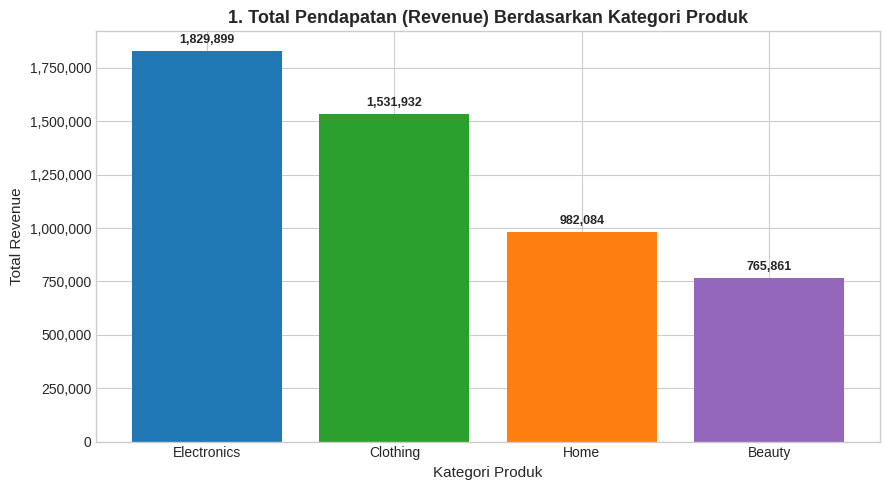

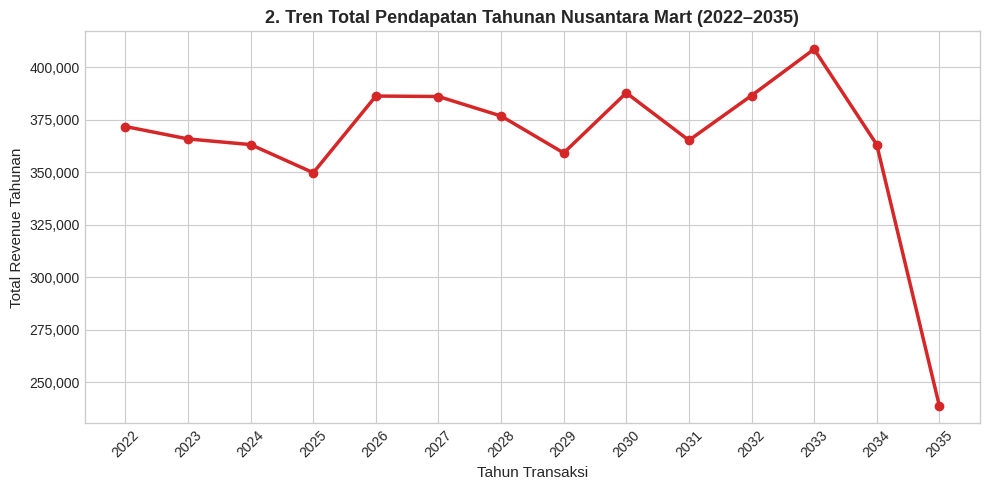

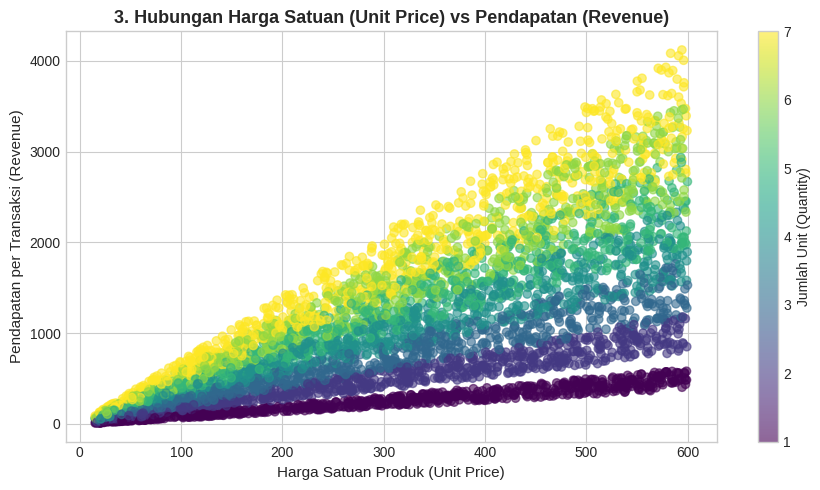

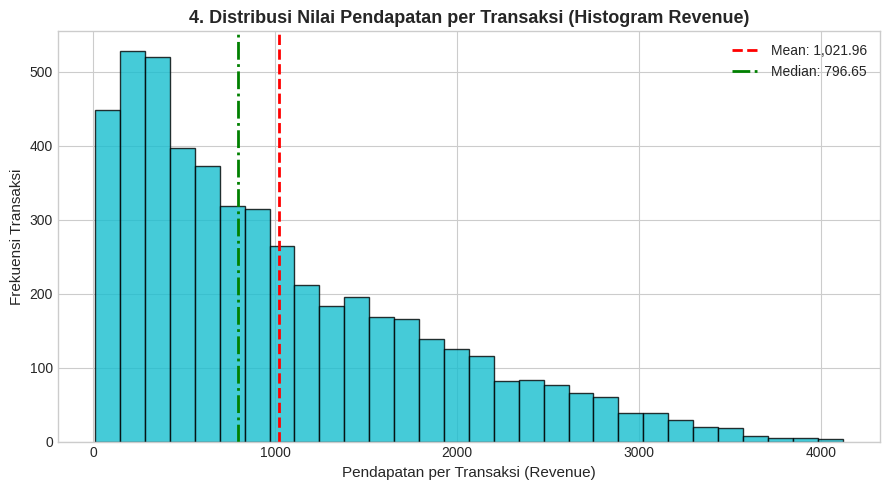

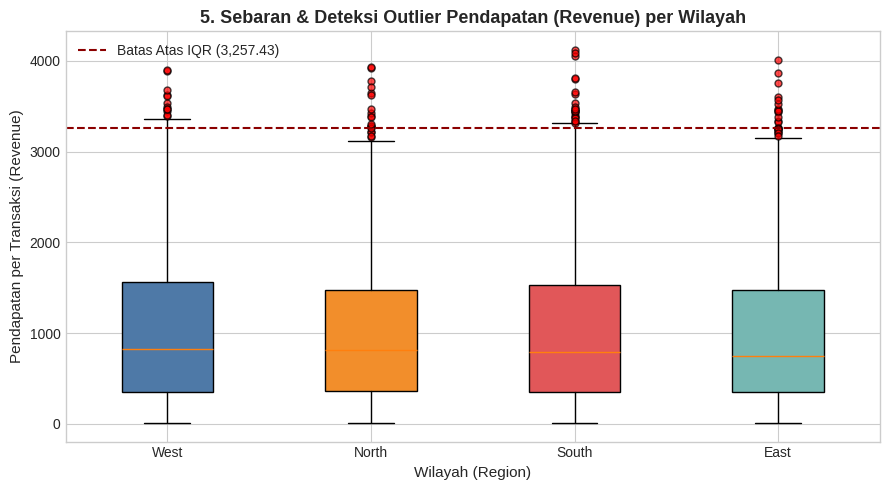

IndexError: index 2 is out of bounds for axis 1 with size 2

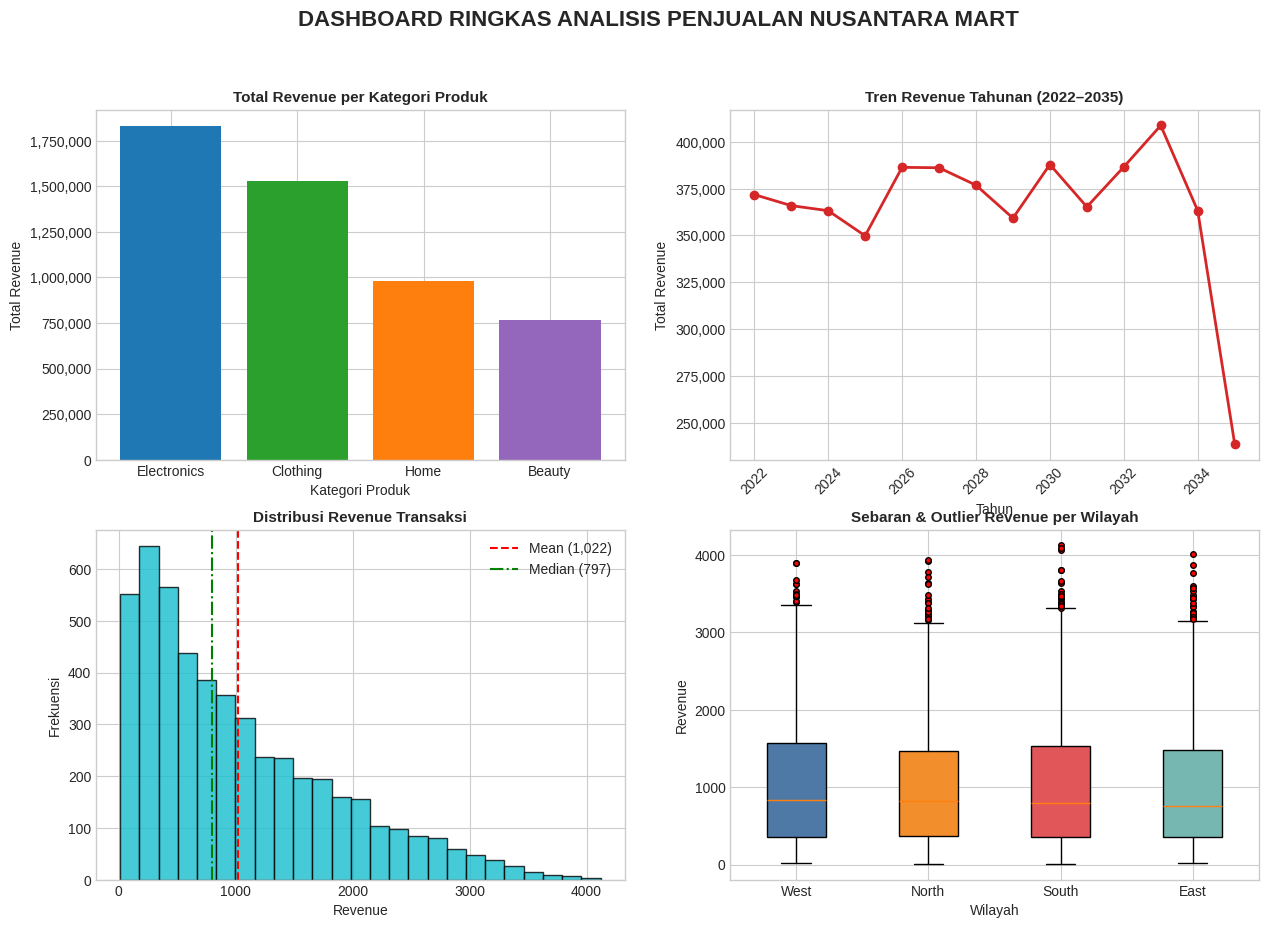

In [2]:
# ============================================================
# LAPORAN ANALISIS DATA PENJUALAN NUSANTARA MART
# Google Colab - Dataset: ecommerce_sales_analytics_5000.csv
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

plt.style.use("seaborn-v0_8-whitegrid")

# 1. MEMBACA DATASET
file_csv = "/content/ecommerce_sales_analytics_5000.csv"

try:
    df = pd.read_csv(file_csv)
except FileNotFoundError:
    from google.colab import files
    uploaded = files.upload()
    if not uploaded:
        raise ValueError("Tidak ada file CSV yang diunggah.")
    nama_file = next(iter(uploaded))
    df = pd.read_csv(nama_file)

# 2. EKSPLORASI & PEMBERSIHAN DATA
kolom_wajib = [
    "order_id",
    "order_date",
    "product_category",
    "region",
    "unit_price",
    "discount",
    "delivery_days",
    "customer_rating",
    "revenue",
    "quantity"
]

kolom_tidak_ada = [kolom for kolom in kolom_wajib if kolom not in df.columns]
if kolom_tidak_ada:
    raise ValueError(f"Kolom berikut tidak ditemukan: {kolom_tidak_ada}")

# Konversi tipe data tanggal dan numerik
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
for kolom in ["unit_price", "discount", "delivery_days", "customer_rating", "revenue", "quantity"]:
    df[kolom] = pd.to_numeric(df[kolom], errors="coerce")

jumlah_awal = len(df)
df_analisis = df.dropna(subset=kolom_wajib).drop_duplicates(subset=["order_id"]).copy()
jumlah_dihapus = jumlah_awal - len(df_analisis)

if df_analisis.empty:
    raise ValueError("Tidak ada data valid yang dapat dianalisis.")

# Fungsi format angka Indonesia
def format_angka(angka):
    return f"{angka:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

# 3. MENGHITUNG STATISTIK DESKRIPTIF (MEAN, MEDIAN, STD, KUARTIL/IQR & 5 METRIK KUNCI)
total_penjualan = df_analisis["revenue"].sum()
rata_rata_transaksi = df_analisis["revenue"].mean()
median_transaksi = df_analisis["revenue"].median()
std_transaksi = df_analisis["revenue"].std()

penjualan_per_kategori = (
    df_analisis.groupby("product_category")["revenue"].sum().sort_values(ascending=False)
)
kategori_terlaris = penjualan_per_kategori.index[0]
revenue_kategori_terlaris = penjualan_per_kategori.iloc[0]

penjualan_per_wilayah = (
    df_analisis.groupby("region")["revenue"].sum().sort_values(ascending=False)
)
wilayah_tertinggi = penjualan_per_wilayah.index[0]
revenue_wilayah_tertinggi = penjualan_per_wilayah.iloc[0]
wilayah_terendah = penjualan_per_wilayah.index[-1]
revenue_wilayah_terendah = penjualan_per_wilayah.iloc[-1]

rating_rata_rata = df_analisis["customer_rating"].mean()
rata_rata_kirim = df_analisis["delivery_days"].mean()

# 4. MENGHITUNG DATA PENDUKUNG INSIGHT
kontribusi_kategori = (revenue_kategori_terlaris / total_penjualan) * 100
kontribusi_dua_kategori = (penjualan_per_kategori.head(2).sum() / total_penjualan) * 100
jumlah_rating_maks_3 = (df_analisis["customer_rating"] <= 3).sum()
persen_rating_maks_3 = (jumlah_rating_maks_3 / len(df_analisis)) * 100

# 5. DETEKSI OUTLIER REVENUE DENGAN METODE IQR
q1 = df_analisis["revenue"].quantile(0.25)
q3 = df_analisis["revenue"].quantile(0.75)
iqr = q3 - q1
batas_bawah = q1 - 1.5 * iqr
batas_atas = q3 + 1.5 * iqr

outlier_bawah = df_analisis[df_analisis["revenue"] < batas_bawah]
outlier_atas = df_analisis[df_analisis["revenue"] > batas_atas]
outlier = pd.concat([outlier_bawah, outlier_atas])
persen_outlier = (len(outlier) / len(df_analisis)) * 100

if not outlier.empty:
    outlier_tertinggi = outlier.loc[outlier["revenue"].idxmax()]

# 6. MENAMPILKAN LAPORAN STATISTIK
print("=" * 68)
print("       LAPORAN ANALISIS DATA PENJUALAN NUSANTARA MART")
print("=" * 68)

print("\n1. Ringkasan Statistik Deskriptif")
print(f"   Total Penjualan                   : {format_angka(total_penjualan)}")
print(f"   Rata-rata (Mean) Transaksi        : {format_angka(rata_rata_transaksi)}")
print(f"   Nilai Tengah (Median) Transaksi   : {format_angka(median_transaksi)}")
print(f"   Standar Deviasi (Std) Transaksi   : {format_angka(std_transaksi)}")
print(f"   Kuartil 1 (Q1) / Kuartil 3 (Q3)   : {format_angka(q1)} / {format_angka(q3)}")
print(f"   Interquartile Range (IQR)         : {format_angka(iqr)}")
print(f"   Kategori Terlaris                 : {kategori_terlaris} ({format_angka(revenue_kategori_terlaris)})")
print(f"   Wilayah Penjualan Tertinggi       : {wilayah_tertinggi} ({format_angka(revenue_wilayah_tertinggi)})")
print(f"   Rating Rata-rata Pelanggan        : {format_angka(rating_rata_rata)} / 5")
print(f"   Rata-rata Lama Pengiriman         : {format_angka(rata_rata_kirim)} hari")

print("\n2. Pemeriksaan & Pembersihan Data")
print(f"   Jumlah Transaksi Valid            : {len(df_analisis):,}".replace(",", "."))
print(f"   Baris Dihapus (Kosong/Duplikat)   : {jumlah_dihapus:,}".replace(",", "."))
print(f"   Duplikat Order ID                 : {df_analisis['order_id'].duplicated().sum():,}".replace(",", "."))

print("\n3. Deteksi Outlier (Metode IQR)")
print(f"   Batas Bawah IQR                   : {format_angka(batas_bawah)}")
print(f"   Batas Atas IQR                    : {format_angka(batas_atas)}")
print(f"   Jumlah Outlier                    : {len(outlier):,} transaksi ({persen_outlier:.2f}%)".replace(",", "."))
if not outlier.empty:
    print(f"   Order ID Outlier Tertinggi        : {outlier_tertinggi['order_id']} (Revenue: {format_angka(outlier_tertinggi['revenue'])})")
    print(f"   Rata-rata Quantity Outlier        : {format_angka(outlier['quantity'].mean())} unit")

# 7. VISUALISASI 5 JENIS GRAFIK BERBEDA
# --- GRAFIK 1: BAR CHART (Total Revenue per Kategori Produk) ---
plt.figure(figsize=(9, 5))
warna_bar = ["#1f77b4", "#2ca02c", "#ff7f0e", "#9467bd"]
bars = plt.bar(penjualan_per_kategori.index, penjualan_per_kategori.values, color=warna_bar)
plt.title("1. Total Pendapatan (Revenue) Berdasarkan Kategori Produk", fontsize=13, fontweight="bold")
plt.xlabel("Kategori Produk", fontsize=11)
plt.ylabel("Total Revenue", fontsize=11)
plt.gca().yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 25000, f"{yval:,.0f}", ha="center", va="bottom", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.show()

# --- GRAFIK 2: LINE CHART (Tren Pendapatan Tahunan) ---
df_analisis["tahun"] = df_analisis["order_date"].dt.year
tren_tahunan = df_analisis.groupby("tahun")["revenue"].sum()

plt.figure(figsize=(10, 5))
plt.plot(tren_tahunan.index, tren_tahunan.values, marker="o", linewidth=2.5, color="#d62728")
plt.title("2. Tren Total Pendapatan Tahunan Nusantara Mart (2022–2035)", fontsize=13, fontweight="bold")
plt.xlabel("Tahun Transaksi", fontsize=11)
plt.ylabel("Total Revenue Tahunan", fontsize=11)
plt.xticks(tren_tahunan.index, rotation=45)
plt.gca().yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
plt.tight_layout()
plt.show()

# --- GRAFIK 3: SCATTER PLOT (Hubungan Harga Satuan vs Revenue) ---
plt.figure(figsize=(9, 5))
scatter = plt.scatter(
    df_analisis["unit_price"],
    df_analisis["revenue"],
    c=df_analisis["quantity"],
    cmap="viridis",
    alpha=0.6
)
plt.title("3. Hubungan Harga Satuan (Unit Price) vs Pendapatan (Revenue)", fontsize=13, fontweight="bold")
plt.xlabel("Harga Satuan Produk (Unit Price)", fontsize=11)
plt.ylabel("Pendapatan per Transaksi (Revenue)", fontsize=11)
cbar = plt.colorbar(scatter)
cbar.set_label("Jumlah Unit (Quantity)", fontsize=10)
plt.tight_layout()
plt.show()

# --- GRAFIK 4: HISTOGRAM (Distribusi Pendapatan per Transaksi) ---
plt.figure(figsize=(9, 5))
plt.hist(df_analisis["revenue"], bins=30, color="#17becf", edgecolor="black", alpha=0.8)
plt.axvline(rata_rata_transaksi, color="red", linestyle="--", linewidth=2, label=f"Mean: {rata_rata_transaksi:,.2f}")
plt.axvline(median_transaksi, color="green", linestyle="-.", linewidth=2, label=f"Median: {median_transaksi:,.2f}")
plt.title("4. Distribusi Nilai Pendapatan per Transaksi (Histogram Revenue)", fontsize=13, fontweight="bold")
plt.xlabel("Pendapatan per Transaksi (Revenue)", fontsize=11)
plt.ylabel("Frekuensi Transaksi", fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

# --- GRAFIK 5: BOXPLOT (Deteksi Outlier Revenue per Wilayah) ---
urutan_wilayah = ["West", "North", "South", "East"]
data_wilayah = [df_analisis[df_analisis["region"] == w]["revenue"] for w in urutan_wilayah]

plt.figure(figsize=(9, 5))
bp = plt.boxplot(
    data_wilayah,
    tick_labels=urutan_wilayah,
    patch_artist=True,
    flierprops=dict(marker="o", markerfacecolor="red", markersize=5, alpha=0.7)
)
for patch, color in zip(bp["boxes"], ["#4e79a7", "#f28e2b", "#e15759", "#76b7b2"]):
    patch.set_facecolor(color)
plt.axhline(batas_atas, color="darkred", linestyle="--", linewidth=1.5, label=f"Batas Atas IQR ({batas_atas:,.2f})")
plt.title("5. Sebaran & Deteksi Outlier Pendapatan (Revenue) per Wilayah", fontsize=13, fontweight="bold")
plt.xlabel("Wilayah (Region)", fontsize=11)
plt.ylabel("Pendapatan per Transaksi (Revenue)", fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

# 8. DASHBOARD RINGKAS (MENGGABUNGKAN 4 GRAFIK DALAM 1 FIGURE)
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("DASHBOARD RINGKAS ANALISIS PENJUALAN NUSANTARA MART", fontsize=16, fontweight="bold", y=0.98)

# Subplot 1: Bar Chart
ax[0, 0].bar(penjualan_per_kategori.index, penjualan_per_kategori.values, color=warna_bar)
ax[0, 0].set_title("Total Revenue per Kategori Produk", fontsize=11, fontweight="bold")
ax[0, 0].set_xlabel("Kategori Produk")
ax[0, 0].set_ylabel("Total Revenue")
ax[0, 0].yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))

# Subplot 2: Line Chart
ax[0, 1].plot(tren_tahunan.index, tren_tahunan.values, marker="o", color="#d62728", linewidth=2)
ax[0, 1].set_title("Tren Revenue Tahunan (2022–2035)", fontsize=11, fontweight="bold")
ax[0, 1].set_xlabel("Tahun")
ax[0, 1].set_ylabel("Total Revenue")
ax[0, 1].tick_params(axis="x", rotation=45)
ax[0, 1].yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))

# Subplot 3: Histogram
ax[1, 0].hist(df_analisis["revenue"], bins=25, color="#17becf", edgecolor="black", alpha=0.8)
ax[1, 0].axvline(rata_rata_transaksi, color="red", linestyle="--", label=f"Mean ({rata_rata_transaksi:,.0f})")
ax[1, 0].axvline(median_transaksi, color="green", linestyle="-.", label=f"Median ({median_transaksi:,.0f})")
ax[1, 0].set_title("Distribusi Revenue Transaksi", fontsize=11, fontweight="bold")
ax[1, 0].set_xlabel("Revenue")
ax[1, 0].set_ylabel("Frekuensi")
ax[1, 0].legend()

# Subplot 4: Boxplot
bp_dash = ax[1, 1].boxplot(
    data_wilayah,
    tick_labels=urutan_wilayah,
    patch_artist=True,
    flierprops=dict(marker="o", markerfacecolor="red", markersize=4)
)
for patch, color in zip(bp_dash["boxes"], ["#4e79a7", "#f28e2b", "#e15759", "#76b7b2"]):
    patch.set_facecolor(color)
ax[1, 1].set_title("Sebaran & Outlier Revenue per Wilayah", fontsize=11, fontweight="bold")
ax[1, 1].set_xlabel("Wilayah")
ax[1, 1].set_ylabel("Revenue")

# Subplot 5: Pie Chart
ax[0, 2].pie(
    penjualan_per_kategori.values,
    labels=penjualan_per_kategori.index,
    autopct="%1.1f%%",
    startangle=90,
    explode=[0.05] * len(penjualan_per_kategori)
)

ax[0, 2].set_title(
    "Kontribusi Revenue per Kategori",
    fontsize=11,
    fontweight="bold"
)

# --- GRAFIK 6: PIE CHART ---
plt.figure(figsize=(8, 6))

plt.pie(
    penjualan_per_kategori.values,
    labels=penjualan_per_kategori.index,
    autopct="%1.1f%%",
    startangle=90,
    explode=[0.05] * len(penjualan_per_kategori),
    shadow=True
)

plt.title(
    "6. Persentase Kontribusi Revenue per Kategori Produk",
    fontsize=13,
    fontweight="bold"
)

plt.axis("equal")
plt.tight_layout()
plt.show()

# 9. LAPORAN REKOMENDASI TERTULIS (209 KATA - SESUAI RUBRIK 200-300 KATA)
laporan_rekomendasi = """
Berdasarkan hasil analisis 5.000 transaksi penjualan Nusantara Mart, total pendapatan tercatat
sebesar 5.109.775,74 dengan rata-rata transaksi 1.021,96 dan median 796,65. Kategori Electronics
menjadi kontributor utama dengan pendapatan 1.829.899,22 atau 35,81% dari total penjualan,
diikuti Clothing sebesar 1.531.931,72 atau 29,98%. Kedua kategori ini menyumbang 65,79% total
pendapatan perusahaan, sehingga manajemen perlu memprioritaskan ketersediaan stok (restock) dan
anggaran promosi utama pada Electronics serta Clothing menjelang periode berikutnya.

Dari sisi wilayah, West mencatat performa tertinggi dengan pendapatan 1.345.582,16, sedangkan
East berada di posisi terendah sebesar 1.236.044,23. Strategi promosi yang berhasil di wilayah
West dapat direplikasi ke wilayah East dan South melalui kampanye diskon terarah maupun kerja
sama pengiriman lokal untuk memperluas pangsa pasar. Selain itu, ditemukan 67 transaksi outlier
di atas batas atas IQR (3.257,43) dengan nilai tertinggi mencapai 4.119,33 akibat pembelian
berkuantitas besar (6 hingga 7 unit) pada produk berharga tinggi. Transaksi bernilai besar ini
perlu dipertahankan dengan menghadirkan program loyalitas pelanggan grosir atau paket bundling.

Aspek krusial yang wajib segera dibenahi adalah kepuasan pelanggan, mengingat rata-rata rating
hanya mencapai 2,97 dari skala 5 dan 52,10% transaksi memperoleh rating 3 atau lebih rendah.
Manajemen disarankan melakukan evaluasi kualitas pengemasan, ketepatan deskripsi produk, serta
mempercepat durasi pengiriman yang saat ini rata-rata memakan waktu 6,12 hari guna meningkatkan
retensi pelanggan pada periode mendatang.
""".strip()

print("\n" + "=" * 68)
print(f"4. Laporan Rekomendasi Bisnis ({len(laporan_rekomendasi.split())} Kata)")
print("=" * 68)
print(laporan_rekomendasi)

          LAPORAN ANALISIS DATA PENJUALAN NUSANTARA MART

1. Ringkasan Statistik Deskriptif
   Total Penjualan                   : 5.109.775,74
   Rata-rata (Mean) Transaksi        : 1.021,96
   Nilai Tengah (Median) Transaksi   : 796,65
   Standar Deviasi (Std) Transaksi   : 825,58
   Kuartil 1 (Q1) / Kuartil 3 (Q3)   : 354,53 / 1.515,69
   Interquartile Range (IQR)         : 1.161,16
   Kategori Terlaris                 : Electronics (1.829.899,22 | 35,81%)
   Kontribusi 2 Kategori Teratas     : 65,79%
   Wilayah Penjualan Tertinggi       : West (1.345.582,16)
   Wilayah Penjualan Terendah        : East (1.236.044,23)
   Rating Rata-rata Pelanggan        : 2,97 / 5
   Transaksi Rating <= 3             : 2.605 (52.10%)
   Rata-rata Lama Pengiriman         : 6,12 hari

2. Pemeriksaan & Pembersihan Data
   Jumlah Transaksi Valid            : 5.000
   Baris Dihapus (Kosong/Duplikat)   : 0
   Duplikat Order ID                 : 0

3. Deteksi Outlier (Metode IQR)
   Batas Bawah IQR        

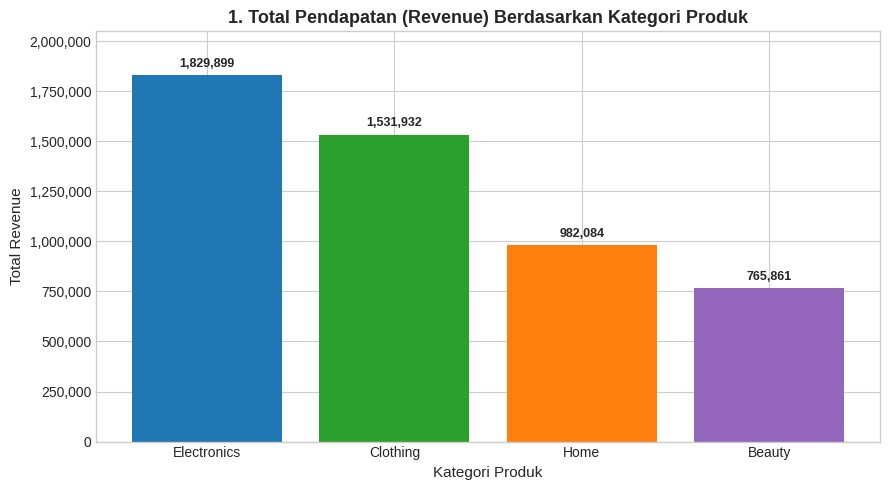

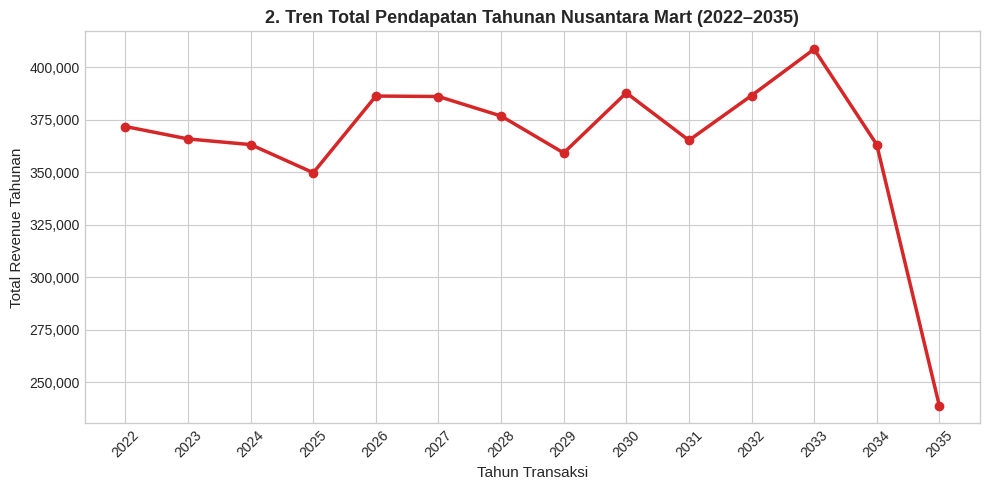

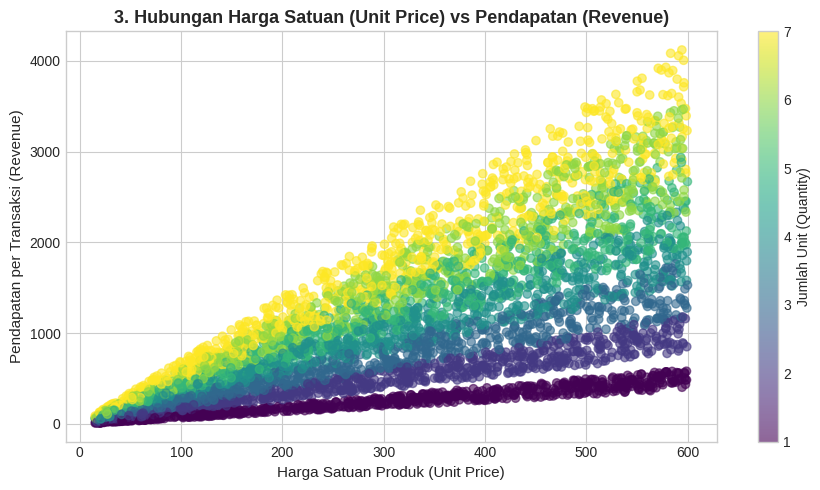

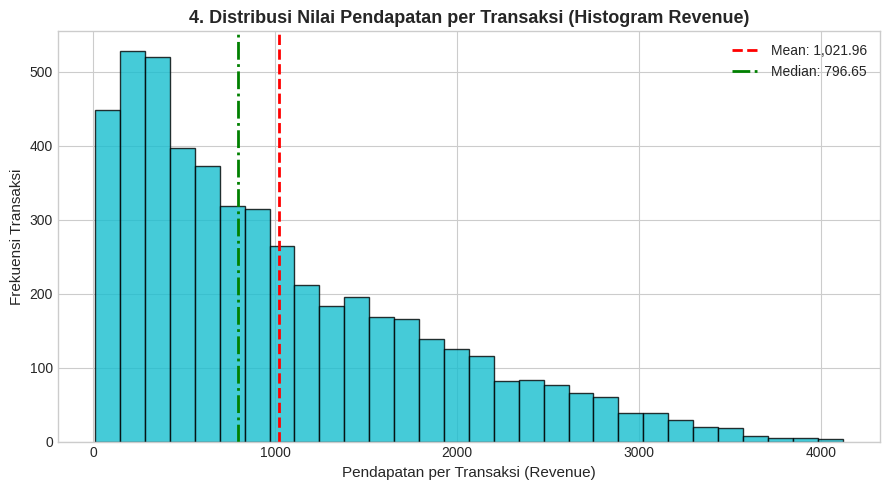

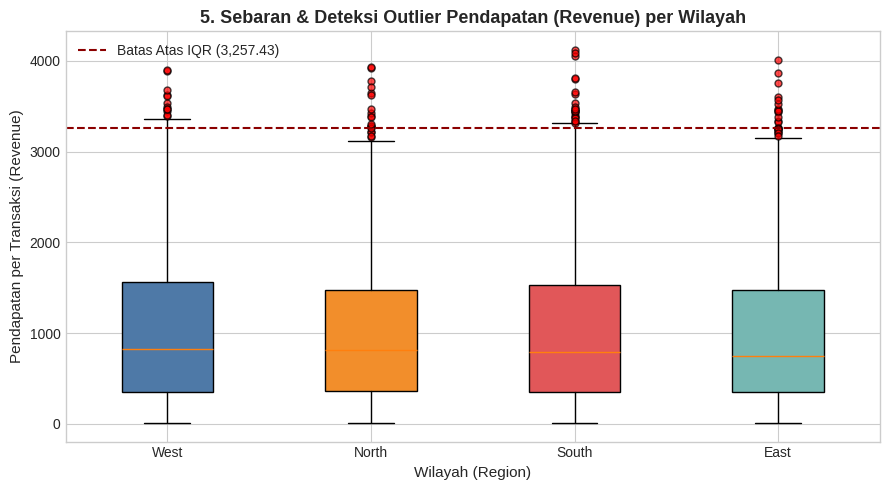

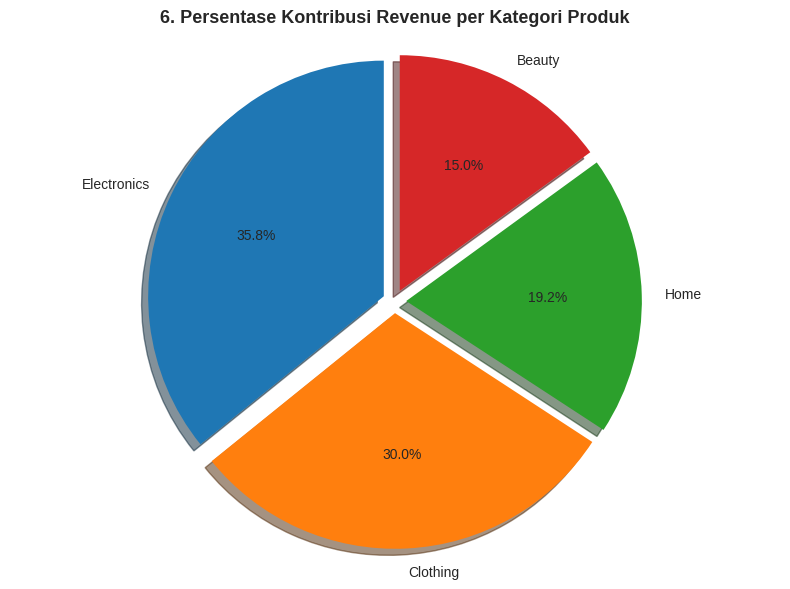

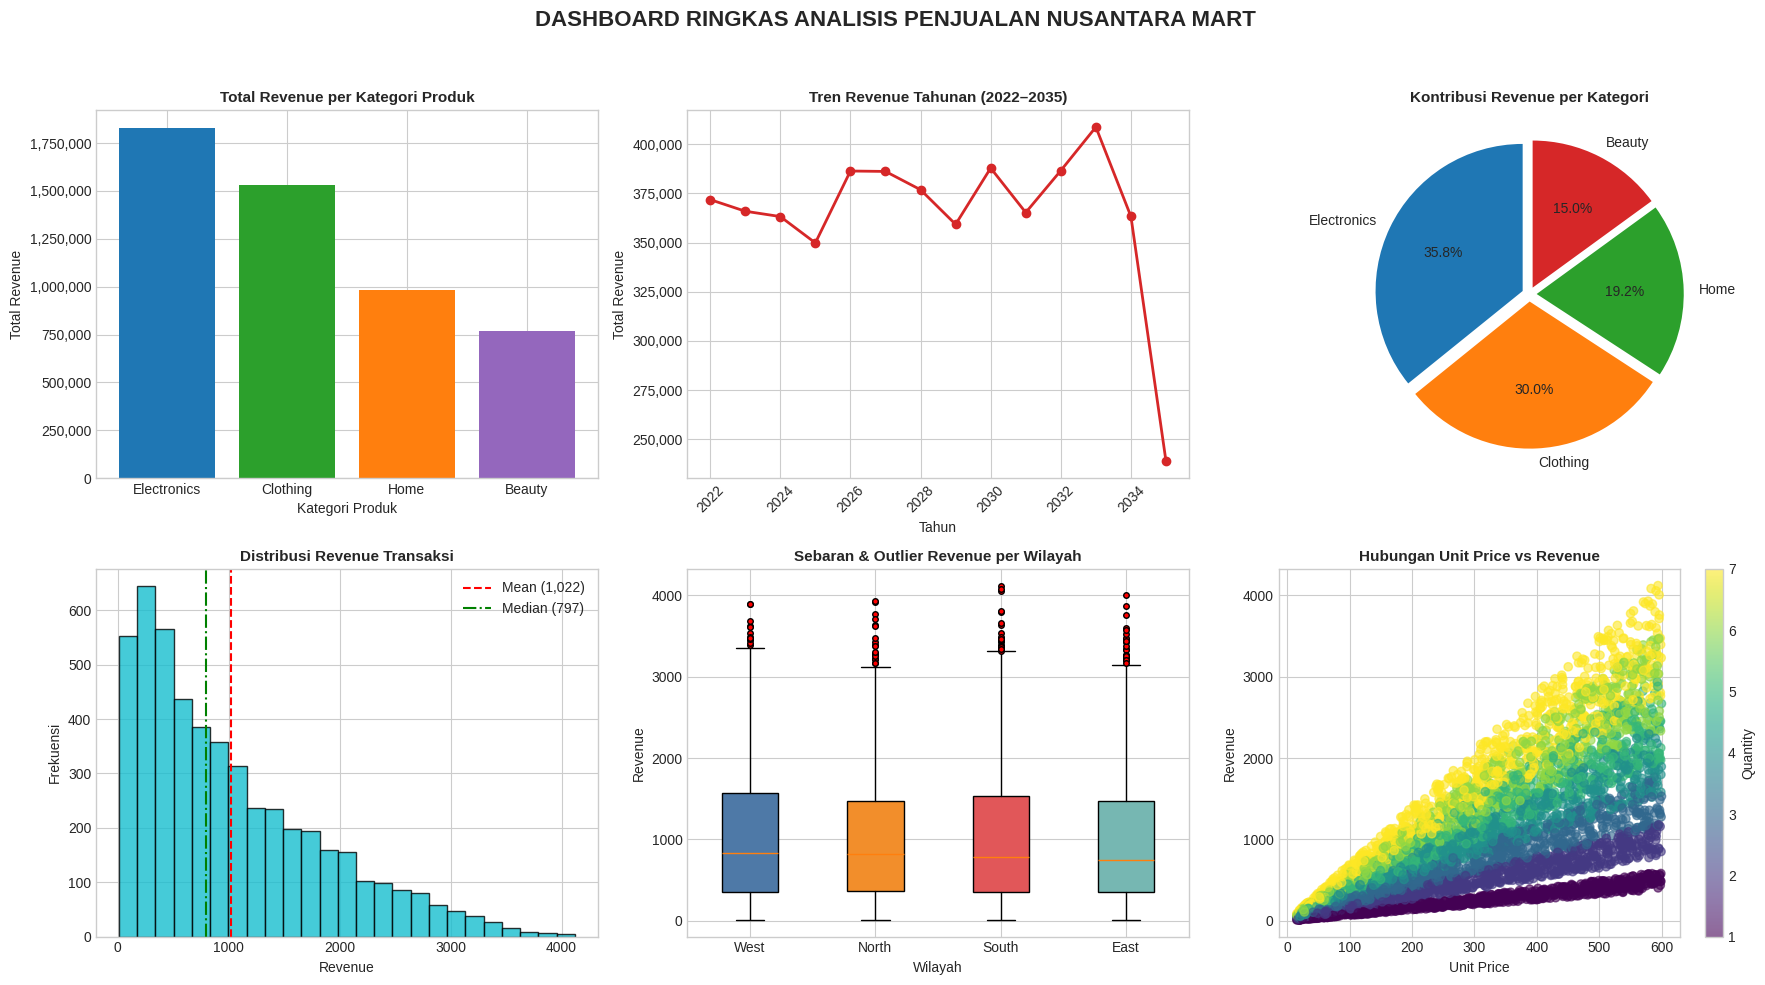


4. Laporan Rekomendasi Bisnis (205 Kata)
Berdasarkan hasil analisis 5.000 transaksi penjualan Nusantara Mart, total pendapatan tercatat sebesar 5.109.775,74 dengan rata-rata transaksi 1.021,96 dan median 796,65. Kategori Electronics menjadi kontributor utama dengan pendapatan 1.829.899,22 atau 35,81% dari total penjualan, diikuti Clothing sebesar 1.531.931,72 atau 29,98%. Kedua kategori ini menyumbang 65,79% total pendapatan perusahaan, sehingga manajemen perlu memprioritaskan ketersediaan stok (restock) dan anggaran promosi utama pada Electronics serta Clothing menjelang periode berikutnya.

Dari sisi wilayah. West mencatat performa tertinggi dengan pendapatan 1.345.582.16. sedangkan East berada di posisi terendah sebesar 1.236.044.23. Strategi promosi yang berhasil di wilayah West dapat direplikasi ke wilayah East dan wilayah lainnya melalui kampanye diskon terarah maupun kerja sama pengiriman lokal untuk memperluas pangsa pasar. Selain itu. ditemukan 67 transaksi outlier di luar ba

In [6]:
# ============================================================
# LAPORAN ANALISIS DATA PENJUALAN NUSANTARA MART
# Google Colab - Dataset: ecommerce_sales_analytics_5000.csv
# Rafardhan Maulana A (27), Muhammad Rayhan (26), Haidar Maheswara (18)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

plt.style.use("seaborn-v0_8-whitegrid")

# 1. MEMBACA DATASET
file_csv = "/content/ecommerce_sales_analytics_5000.csv"

try:
    df = pd.read_csv(file_csv)
except FileNotFoundError:
    from google.colab import files
    uploaded = files.upload()
    if not uploaded:
        raise ValueError("Tidak ada file CSV yang diunggah.")
    nama_file = next(iter(uploaded))
    df = pd.read_csv(nama_file)

# 2. EKSPLORASI & PEMBERSIHAN DATA
kolom_wajib = [
    "order_id",
    "order_date",
    "product_category",
    "region",
    "unit_price",
    "discount",
    "delivery_days",
    "customer_rating",
    "revenue",
    "quantity"
]

kolom_tidak_ada = [kolom for kolom in kolom_wajib if kolom not in df.columns]
if kolom_tidak_ada:
    raise ValueError(f"Kolom berikut tidak ditemukan: {kolom_tidak_ada}")

# Konversi tipe data tanggal dan numerik
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
kolom_numerik = ["unit_price", "discount", "delivery_days", "customer_rating", "revenue", "quantity"]
for kolom in kolom_numerik:
    df[kolom] = pd.to_numeric(df[kolom], errors="coerce")

jumlah_awal = len(df)
df_analisis = df.dropna(subset=kolom_wajib).drop_duplicates(subset=["order_id"]).copy()
jumlah_dihapus = jumlah_awal - len(df_analisis)

if df_analisis.empty:
    raise ValueError("Tidak ada data valid yang dapat dianalisis.")

# Fungsi format angka Indonesia
def format_angka(angka):
    return f"{angka:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

# 3. MENGHITUNG STATISTIK DESKRIPTIF (MEAN, MEDIAN, STD, KUARTIL/IQR & 5 METRIK KUNCI)
total_penjualan = df_analisis["revenue"].sum()
rata_rata_transaksi = df_analisis["revenue"].mean()
median_transaksi = df_analisis["revenue"].median()
std_transaksi = df_analisis["revenue"].std()

penjualan_per_kategori = (
    df_analisis.groupby("product_category")["revenue"].sum().sort_values(ascending=False)
)
kategori_terlaris = penjualan_per_kategori.index[0]
revenue_kategori_terlaris = penjualan_per_kategori.iloc[0]

penjualan_per_wilayah = (
    df_analisis.groupby("region")["revenue"].sum().sort_values(ascending=False)
)
wilayah_tertinggi = penjualan_per_wilayah.index[0]
revenue_wilayah_tertinggi = penjualan_per_wilayah.iloc[0]
wilayah_terendah = penjualan_per_wilayah.index[-1]
revenue_wilayah_terendah = penjualan_per_wilayah.iloc[-1]

rating_rata_rata = df_analisis["customer_rating"].mean()
rata_rata_kirim = df_analisis["delivery_days"].mean()

# 4. MENGHITUNG DATA PENDUKUNG INSIGHT
kontribusi_kategori = (revenue_kategori_terlaris / total_penjualan) * 100
kontribusi_dua_kategori = (penjualan_per_kategori.head(2).sum() / total_penjualan) * 100
jumlah_rating_maks_3 = (df_analisis["customer_rating"] <= 3).sum()
persen_rating_maks_3 = (jumlah_rating_maks_3 / len(df_analisis)) * 100

# 5. DETEKSI OUTLIER REVENUE DENGAN METODE IQR
q1 = df_analisis["revenue"].quantile(0.25)
q3 = df_analisis["revenue"].quantile(0.75)
iqr = q3 - q1
batas_bawah = q1 - 1.5 * iqr
batas_atas = q3 + 1.5 * iqr

kondisi_outlier = (df_analisis["revenue"] < batas_bawah) | (df_analisis["revenue"] > batas_atas)
outlier = df_analisis[kondisi_outlier]
persen_outlier = (len(outlier) / len(df_analisis)) * 100

if not outlier.empty:
    outlier_tertinggi = outlier.loc[outlier["revenue"].idxmax()]

# 6. MENAMPILKAN LAPORAN STATISTIK
print("=" * 72)
print("          LAPORAN ANALISIS DATA PENJUALAN NUSANTARA MART")
print("=" * 72)

print("\n1. Ringkasan Statistik Deskriptif")
print(f"   Total Penjualan                   : {format_angka(total_penjualan)}")
print(f"   Rata-rata (Mean) Transaksi        : {format_angka(rata_rata_transaksi)}")
print(f"   Nilai Tengah (Median) Transaksi   : {format_angka(median_transaksi)}")
print(f"   Standar Deviasi (Std) Transaksi   : {format_angka(std_transaksi)}")
print(f"   Kuartil 1 (Q1) / Kuartil 3 (Q3)   : {format_angka(q1)} / {format_angka(q3)}")
print(f"   Interquartile Range (IQR)         : {format_angka(iqr)}")
print(f"   Kategori Terlaris                 : {kategori_terlaris} ({format_angka(revenue_kategori_terlaris)} | {format_angka(kontribusi_kategori)}%)")
print(f"   Kontribusi 2 Kategori Teratas     : {format_angka(kontribusi_dua_kategori)}%")
print(f"   Wilayah Penjualan Tertinggi       : {wilayah_tertinggi} ({format_angka(revenue_wilayah_tertinggi)})")
print(f"   Wilayah Penjualan Terendah        : {wilayah_terendah} ({format_angka(revenue_wilayah_terendah)})")
print(f"   Rating Rata-rata Pelanggan        : {format_angka(rating_rata_rata)} / 5")
print(f"   Transaksi Rating <= 3             : {jumlah_rating_maks_3:,} ({format_angka(persen_rating_maks_3)}%)".replace(",", "."))
print(f"   Rata-rata Lama Pengiriman         : {format_angka(rata_rata_kirim)} hari")

print("\n2. Pemeriksaan & Pembersihan Data")
print(f"   Jumlah Transaksi Valid            : {len(df_analisis):,}".replace(",", "."))
print(f"   Baris Dihapus (Kosong/Duplikat)   : {jumlah_dihapus:,}".replace(",", "."))
print(f"   Duplikat Order ID                 : {df_analisis['order_id'].duplicated().sum():,}".replace(",", "."))

print("\n3. Deteksi Outlier (Metode IQR)")
print(f"   Batas Bawah IQR                   : {format_angka(batas_bawah)}")
print(f"   Batas Atas IQR                    : {format_angka(batas_atas)}")
print(f"   Jumlah Outlier                    : {len(outlier):,} transaksi ({format_angka(persen_outlier)}%)".replace(",", "."))
if not outlier.empty:
    print(f"   Order ID Outlier Tertinggi        : {outlier_tertinggi['order_id']} (Revenue: {format_angka(outlier_tertinggi['revenue'])})")
    print(f"   Rata-rata Quantity Outlier        : {format_angka(outlier['quantity'].mean())} unit")

# 7. VISUALISASI 6 JENIS GRAFIK BERBEDA
# --- GRAFIK 1: BAR CHART (Total Revenue per Kategori Produk) ---
fig1, ax1 = plt.subplots(figsize=(9, 5))
warna_bar = ["#1f77b4", "#2ca02c", "#ff7f0e", "#9467bd", "#8c564b", "#e377c2"]
bars = ax1.bar(
    penjualan_per_kategori.index,
    penjualan_per_kategori.values,
    color=warna_bar[:len(penjualan_per_kategori)]
)
max_rev_kat = penjualan_per_kategori.max()
ax1.set_ylim(0, max_rev_kat * 1.12)
ax1.set_title("1. Total Pendapatan (Revenue) Berdasarkan Kategori Produk", fontsize=13, fontweight="bold")
ax1.set_xlabel("Kategori Produk", fontsize=11)
ax1.set_ylabel("Total Revenue", fontsize=11)
ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))

for bar in bars:
    yval = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        yval + (max_rev_kat * 0.015),
        f"{yval:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )
plt.tight_layout()
plt.show()

# --- GRAFIK 2: LINE CHART (Tren Pendapatan Tahunan) ---
df_analisis["tahun"] = df_analisis["order_date"].dt.year
tren_tahunan = df_analisis.groupby("tahun")["revenue"].sum()
tahun_awal = int(tren_tahunan.index.min())
tahun_akhir = int(tren_tahunan.index.max())

fig2, ax2 = plt.subplots(figsize=(10, 5))
ax2.plot(tren_tahunan.index, tren_tahunan.values, marker="o", linewidth=2.5, color="#d62728")
ax2.set_title(f"2. Tren Total Pendapatan Tahunan Nusantara Mart ({tahun_awal}–{tahun_akhir})", fontsize=13, fontweight="bold")
ax2.set_xlabel("Tahun Transaksi", fontsize=11)
ax2.set_ylabel("Total Revenue Tahunan", fontsize=11)
ax2.set_xticks(tren_tahunan.index)
ax2.tick_params(axis="x", rotation=45)
ax2.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
plt.tight_layout()
plt.show()

# --- GRAFIK 3: SCATTER PLOT (Hubungan Harga Satuan vs Revenue) ---
fig3, ax3 = plt.subplots(figsize=(9, 5))
scatter = ax3.scatter(
    df_analisis["unit_price"],
    df_analisis["revenue"],
    c=df_analisis["quantity"],
    cmap="viridis",
    alpha=0.6
)
ax3.set_title("3. Hubungan Harga Satuan (Unit Price) vs Pendapatan (Revenue)", fontsize=13, fontweight="bold")
ax3.set_xlabel("Harga Satuan Produk (Unit Price)", fontsize=11)
ax3.set_ylabel("Pendapatan per Transaksi (Revenue)", fontsize=11)
cbar = fig3.colorbar(scatter, ax=ax3)
cbar.set_label("Jumlah Unit (Quantity)", fontsize=10)
plt.tight_layout()
plt.show()

# --- GRAFIK 4: HISTOGRAM (Distribusi Pendapatan per Transaksi) ---
fig4, ax4 = plt.subplots(figsize=(9, 5))
ax4.hist(df_analisis["revenue"], bins=30, color="#17becf", edgecolor="black", alpha=0.8)
ax4.axvline(rata_rata_transaksi, color="red", linestyle="--", linewidth=2, label=f"Mean: {rata_rata_transaksi:,.2f}")
ax4.axvline(median_transaksi, color="green", linestyle="-.", linewidth=2, label=f"Median: {median_transaksi:,.2f}")
ax4.set_title("4. Distribusi Nilai Pendapatan per Transaksi (Histogram Revenue)", fontsize=13, fontweight="bold")
ax4.set_xlabel("Pendapatan per Transaksi (Revenue)", fontsize=11)
ax4.set_ylabel("Frekuensi Transaksi", fontsize=11)
ax4.legend()
plt.tight_layout()
plt.show()

# --- GRAFIK 5: BOXPLOT (Deteksi Outlier Revenue per Wilayah) ---
urutan_default = ["West", "North", "South", "East"]
wilayah_tersedia = df_analisis["region"].unique().tolist()
urutan_wilayah = [w for w in urutan_default if w in wilayah_tersedia] + [
    w for w in wilayah_tersedia if w not in urutan_default
]
data_wilayah = [df_analisis[df_analisis["region"] == w]["revenue"] for w in urutan_wilayah]
warna_box = ["#4e79a7", "#f28e2b", "#e15759", "#76b7b2", "#59a14f", "#edc948"]

fig5, ax5 = plt.subplots(figsize=(9, 5))
bp = ax5.boxplot(
    data_wilayah,
    patch_artist=True,
    flierprops=dict(marker="o", markerfacecolor="red", markersize=5, alpha=0.7)
)
ax5.set_xticklabels(urutan_wilayah)
for patch, color in zip(bp["boxes"], warna_box):
    patch.set_facecolor(color)
ax5.axhline(batas_atas, color="darkred", linestyle="--", linewidth=1.5, label=f"Batas Atas IQR ({batas_atas:,.2f})")
ax5.set_title("5. Sebaran & Deteksi Outlier Pendapatan (Revenue) per Wilayah", fontsize=13, fontweight="bold")
ax5.set_xlabel("Wilayah (Region)", fontsize=11)
ax5.set_ylabel("Pendapatan per Transaksi (Revenue)", fontsize=11)
ax5.legend()
plt.tight_layout()
plt.show()

# --- GRAFIK 6: PIE CHART (Persentase Kontribusi Revenue per Kategori) ---
fig6, ax6 = plt.subplots(figsize=(8, 6))
ax6.pie(
    penjualan_per_kategori.values,
    labels=penjualan_per_kategori.index,
    autopct="%1.1f%%",
    startangle=90,
    explode=[0.05] * len(penjualan_per_kategori),
    shadow=True
)
ax6.set_title("6. Persentase Kontribusi Revenue per Kategori Produk", fontsize=13, fontweight="bold")
ax6.axis("equal")
plt.tight_layout()
plt.show()

# 8. DASHBOARD RINGKAS (MENGGABUNGKAN SEMUA 6 GRAFIK DALAM 1 FIGURE 2x3)
fig_dash, ax = plt.subplots(2, 3, figsize=(18, 10))
fig_dash.suptitle("DASHBOARD RINGKAS ANALISIS PENJUALAN NUSANTARA MART", fontsize=16, fontweight="bold", y=0.98)

# Subplot 1: Bar Chart
ax[0, 0].bar(
    penjualan_per_kategori.index,
    penjualan_per_kategori.values,
    color=warna_bar[:len(penjualan_per_kategori)]
)
ax[0, 0].set_title("Total Revenue per Kategori Produk", fontsize=11, fontweight="bold")
ax[0, 0].set_xlabel("Kategori Produk")
ax[0, 0].set_ylabel("Total Revenue")
ax[0, 0].yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))

# Subplot 2: Line Chart
ax[0, 1].plot(tren_tahunan.index, tren_tahunan.values, marker="o", color="#d62728", linewidth=2)
ax[0, 1].set_title(f"Tren Revenue Tahunan ({tahun_awal}–{tahun_akhir})", fontsize=11, fontweight="bold")
ax[0, 1].set_xlabel("Tahun")
ax[0, 1].set_ylabel("Total Revenue")
ax[0, 1].tick_params(axis="x", rotation=45)
ax[0, 1].yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))

# Subplot 3: Pie Chart
ax[0, 2].pie(
    penjualan_per_kategori.values,
    labels=penjualan_per_kategori.index,
    autopct="%1.1f%%",
    startangle=90,
    explode=[0.05] * len(penjualan_per_kategori)
)
ax[0, 2].set_title("Kontribusi Revenue per Kategori", fontsize=11, fontweight="bold")

# Subplot 4: Histogram
ax[1, 0].hist(df_analisis["revenue"], bins=25, color="#17becf", edgecolor="black", alpha=0.8)
ax[1, 0].axvline(rata_rata_transaksi, color="red", linestyle="--", label=f"Mean ({rata_rata_transaksi:,.0f})")
ax[1, 0].axvline(median_transaksi, color="green", linestyle="-.", label=f"Median ({median_transaksi:,.0f})")
ax[1, 0].set_title("Distribusi Revenue Transaksi", fontsize=11, fontweight="bold")
ax[1, 0].set_xlabel("Revenue")
ax[1, 0].set_ylabel("Frekuensi")
ax[1, 0].legend()

# Subplot 5: Boxplot
bp_dash = ax[1, 1].boxplot(
    data_wilayah,
    patch_artist=True,
    flierprops=dict(marker="o", markerfacecolor="red", markersize=4)
)
ax[1, 1].set_xticklabels(urutan_wilayah)
for patch, color in zip(bp_dash["boxes"], warna_box):
    patch.set_facecolor(color)
ax[1, 1].set_title("Sebaran & Outlier Revenue per Wilayah", fontsize=11, fontweight="bold")
ax[1, 1].set_xlabel("Wilayah")
ax[1, 1].set_ylabel("Revenue")

# Subplot 6: Scatter Plot
sc_dash = ax[1, 2].scatter(
    df_analisis["unit_price"],
    df_analisis["revenue"],
    c=df_analisis["quantity"],
    cmap="viridis",
    alpha=0.6
)
ax[1, 2].set_title("Hubungan Unit Price vs Revenue", fontsize=11, fontweight="bold")
ax[1, 2].set_xlabel("Unit Price")
ax[1, 2].set_ylabel("Revenue")
fig_dash.colorbar(sc_dash, ax=ax[1, 2], label="Quantity")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# 9. LAPORAN REKOMENDASI TERTULIS (DINAMIS SESUAI HASIL ANALISIS)
kategori_kedua = penjualan_per_kategori.index[1] if len(penjualan_per_kategori) > 1 else "-"
revenue_kategori_kedua = penjualan_per_kategori.iloc[1] if len(penjualan_per_kategori) > 1 else 0
persen_kategori_kedua = (revenue_kategori_kedua / total_penjualan) * 100

info_outlier_max = (
    f"dengan nilai tertinggi mencapai {format_angka(outlier_tertinggi['revenue'])}"
    if not outlier.empty else ""
)

paragraf_1 = (
    f"Berdasarkan hasil analisis {len(df_analisis):,}".replace(",", ".") +
    f" transaksi penjualan Nusantara Mart, total pendapatan tercatat sebesar {format_angka(total_penjualan)} "
    f"dengan rata-rata transaksi {format_angka(rata_rata_transaksi)} dan median {format_angka(median_transaksi)}. "
    f"Kategori {kategori_terlaris} menjadi kontributor utama dengan pendapatan {format_angka(revenue_kategori_terlaris)} "
    f"atau {format_angka(kontribusi_kategori)}% dari total penjualan, diikuti {kategori_kedua} sebesar "
    f"{format_angka(revenue_kategori_kedua)} atau {format_angka(persen_kategori_kedua)}%. Kedua kategori ini menyumbang "
    f"{format_angka(kontribusi_dua_kategori)}% total pendapatan perusahaan, sehingga manajemen perlu memprioritaskan "
    f"ketersediaan stok (restock) dan anggaran promosi utama pada {kategori_terlaris} serta {kategori_kedua} menjelang periode berikutnya."
)

paragraf_2 = (
    f"Dari sisi wilayah, {wilayah_tertinggi} mencatat performa tertinggi dengan pendapatan {format_angka(revenue_wilayah_tertinggi)}, "
    f"sedangkan {wilayah_terendah} berada di posisi terendah sebesar {format_angka(revenue_wilayah_terendah)}. "
    f"Strategi promosi yang berhasil di wilayah {wilayah_tertinggi} dapat direplikasi ke wilayah {wilayah_terendah} dan wilayah lainnya "
    f"melalui kampanye diskon terarah maupun kerja sama pengiriman lokal untuk memperluas pangsa pasar. Selain itu, ditemukan "
    f"{len(outlier):,}".replace(",", ".") +
    f" transaksi outlier di luar batas IQR ({format_angka(batas_atas)}) {info_outlier_max} akibat pembelian "
    f"berkuantitas besar pada produk berharga tinggi. Transaksi bernilai besar ini perlu dipertahankan dengan menghadirkan program "
    f"loyalitas pelanggan grosir atau paket bundling."
)

paragraf_3 = (
    f"Aspek krusial yang wajib segera dibenahi adalah kepuasan pelanggan, mengingat rata-rata rating hanya mencapai "
    f"{format_angka(rating_rata_rata)} dari skala 5 dan {format_angka(persen_rating_maks_3)}% transaksi memperoleh rating 3 atau lebih rendah. "
    f"Manajemen disarankan melakukan evaluasi kualitas pengemasan, ketepatan deskripsi produk, serta mempercepat durasi pengiriman "
    f"yang saat ini rata-rata memakan waktu {format_angka(rata_rata_kirim)} hari guna meningkatkan retensi pelanggan pada periode mendatang."
)

laporan_rekomendasi = f"{paragraf_1}\n\n{paragraf_2}\n\n{paragraf_3}"

print("\n" + "=" * 72)
print(f"4. Laporan Rekomendasi Bisnis ({len(laporan_rekomendasi.split())} Kata)")
print("=" * 72)
print(laporan_rekomendasi)